In [1]:
import os
import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
%matplotlib inline

In [2]:
sam1 = sc.read_10x_mtx('sample1',  var_names='gene_symbols', cache=True)
sam1.var_names_make_unique()
sam1.obs_names_make_unique()
sam1

AnnData object with n_obs × n_vars = 13141 × 38606
    var: 'gene_ids', 'feature_types'

In [3]:
sam2 = sc.read_10x_mtx(path='sample2', var_names='gene_symbols', cache=True)
sam2

AnnData object with n_obs × n_vars = 13113 × 38606
    var: 'gene_ids', 'feature_types'

In [4]:
sam2.var_names_make_unique()
sam2.obs_names_make_unique()

In [5]:
sam2

AnnData object with n_obs × n_vars = 13113 × 38606
    var: 'gene_ids', 'feature_types'

In [6]:
sam1.obs['sample'] = 'sample1'
sam2.obs['sample'] = 'sample2'

In [7]:
adata_merged = ad.concat([sam1, sam2], label='sample')
adata_merged

/home/sreeram/miniconda3/envs/scanpy_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 26254 × 38606
    obs: 'sample'

In [8]:
adata_merged.var = pd.DataFrame({'gene': adata_merged.var_names}, index = adata_merged.var_names)
adata_merged

AnnData object with n_obs × n_vars = 26254 × 38606
    obs: 'sample'
    var: 'gene'

In [9]:
adata_merged.var["mt"] = sam2.var_names.str.startswith("MT-")
adata_merged.var["ribo"] = sam2.var_names.str.startswith(("RPL", "RPS"))
sc.pp.calculate_qc_metrics(adata_merged, qc_vars=['mt', 'ribo'], percent_top=False, log1p=False, inplace=True)

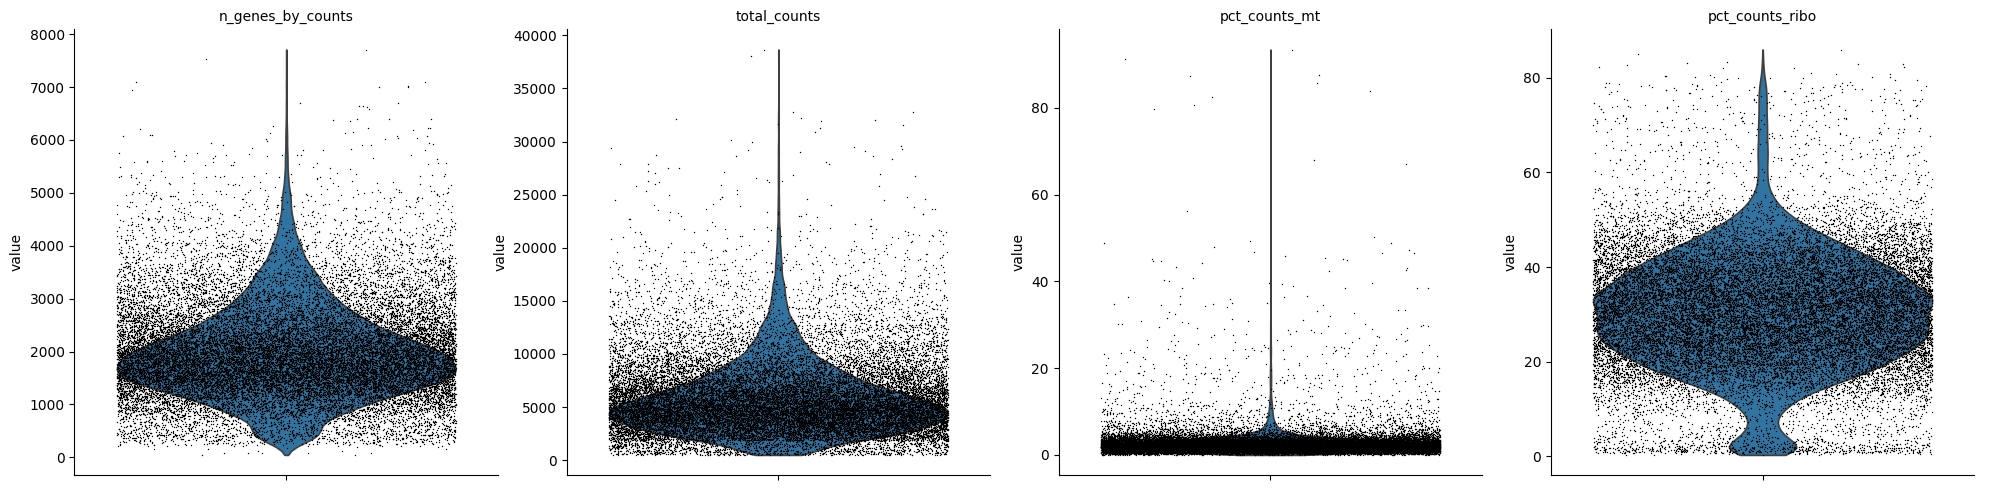

In [10]:
sc.pl.violin(
    adata_merged,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo"],
    jitter=0.4,
    multi_panel=True,
)

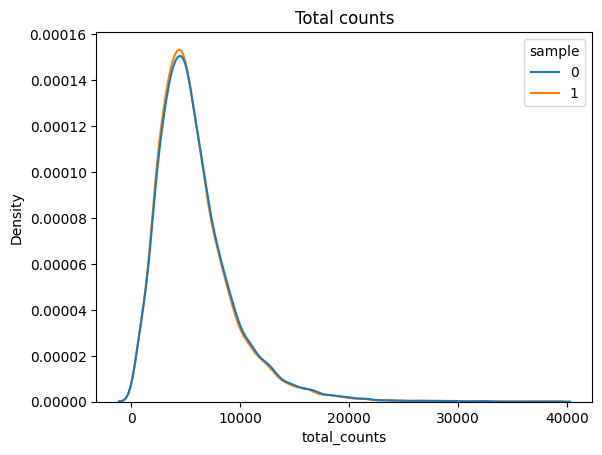

In [11]:
sns.kdeplot(
    data=adata_merged.obs,
    x='total_counts',
    hue='sample',
    common_norm=False
)
plt.title('Total counts')
plt.show()

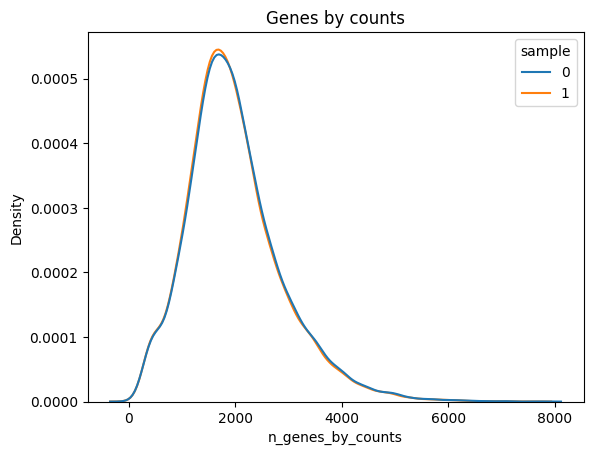

In [12]:
sns.kdeplot(
    data=adata_merged.obs,
    x='n_genes_by_counts',
    hue='sample',
    common_norm=False
)
plt.title('Genes by counts')
plt.show()

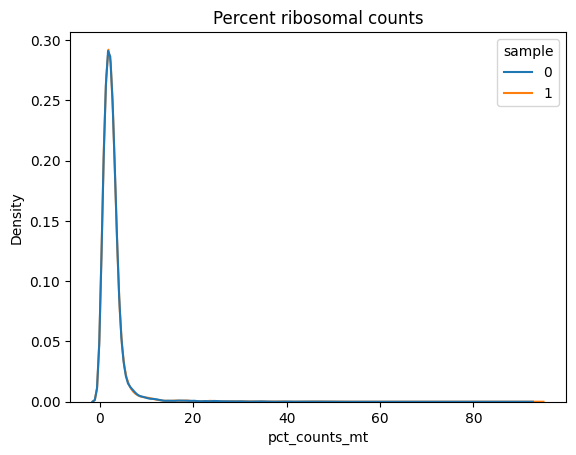

In [13]:
sns.kdeplot(
    data=adata_merged.obs,
    x='pct_counts_mt',
    hue='sample',
    common_norm=False
)
plt.title('Percent ribosomal counts')
plt.show()

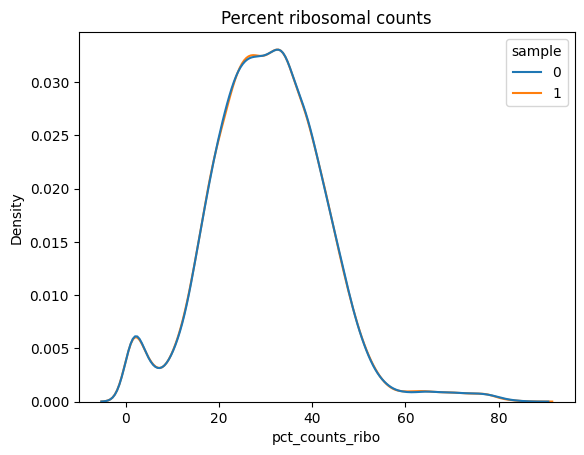

In [14]:
sns.kdeplot(
    data=adata_merged.obs,
    x='pct_counts_ribo',
    hue='sample',
    common_norm=False
)
plt.title('Percent ribosomal counts')
plt.show()

#### Joint QC

In [15]:
qc_set1 = (adata_merged.obs['pct_counts_mt'] < 10) & \
      (adata_merged.obs['n_genes_by_counts'].between(200, 3000))
qc_set1.sum()

np.int64(22478)

In [16]:
adata_merged

AnnData object with n_obs × n_vars = 26254 × 38606
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [17]:
adata_filtered = adata_merged[qc_set1, :].copy()
adata_filtered

/home/sreeram/miniconda3/envs/scanpy_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 22478 × 38606
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

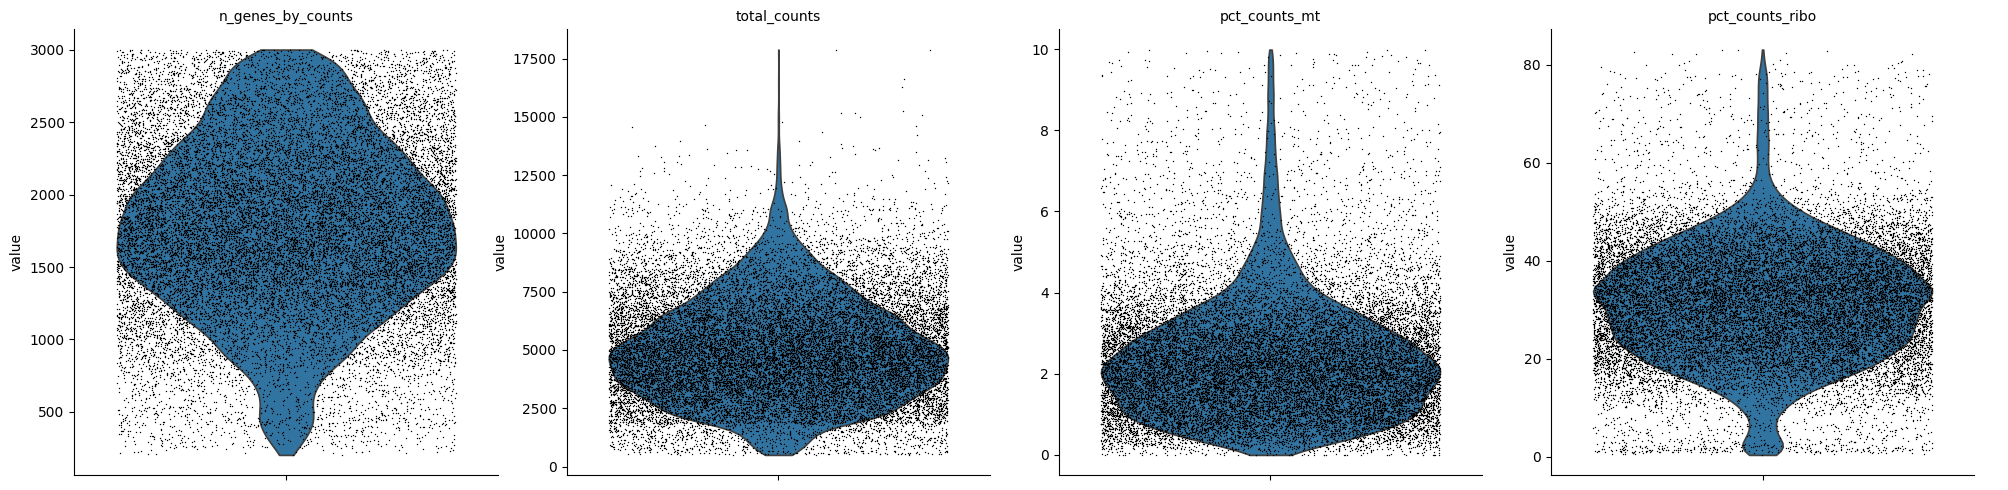

In [18]:
sc.pl.violin(adata_filtered, keys=["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo"], jitter=0.4, multi_panel=True)

In [19]:
sc.pp.filter_genes(adata_filtered, min_cells=5) # gene expressed in atleast 5 cells
adata_filtered

/home/sreeram/miniconda3/envs/scanpy_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 22478 × 25051
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'

In [20]:
sc.pp.normalize_total(adata_filtered, target_sum=1e4)
sc.pp.log1p(adata_filtered)
adata_filtered

AnnData object with n_obs × n_vars = 22478 × 25051
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p'

#### Feature reduction

In [21]:
hvg_df = sc.pp.highly_variable_genes(adata_filtered, n_top_genes=2000, subset=True, flavor='seurat_v3', inplace=False)
hvg_df.head()

/home/sreeram/miniconda3/envs/scanpy_env/lib/python3.10/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)


,means,variances,gene_name,highly_variable_rank,variances_norm,highly_variable
TTLL10,0.000523,0.000761,TTLL10,726.0,1.241065,True
SCNN1D,0.002857,0.003930,SCNN1D,1269.0,1.174199,True
MRPL20-DT,0.001514,0.002013,MRPL20-DT,1862.0,1.134189,True
CFAP74,0.000899,0.001315,CFAP74,707.0,1.246175,True
CCDC27,0.000452,0.000610,CCDC27,1439.0,1.160500,True


In [22]:
adata_filtered

AnnData object with n_obs × n_vars = 22478 × 25051
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p'

In [23]:
top10_hvgs = hvg_df.sort_values(by='highly_variable_rank').head(10)['gene_name'].to_list()

In [24]:
top10_hvgs

['S100A9',
 'S100A8',
 'FN1',
 'LYZ',
 'MT2A',
 'SPP1',
 'PRTN3',
 'ELANE',
 'CXCL8',
 'CLC']

/tmp/ipykernel_4245/3996557543.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


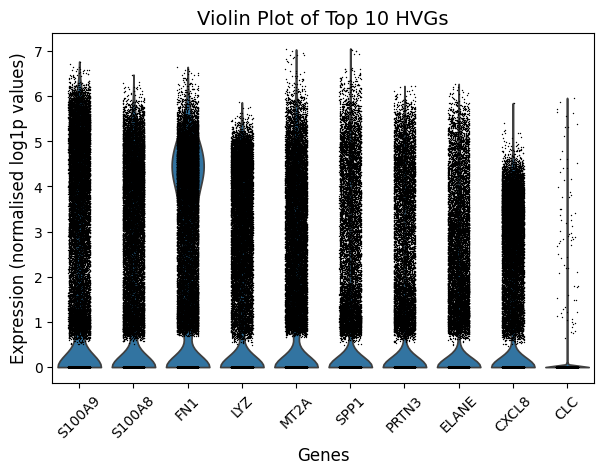

In [25]:
# Plot without immediately showing it
sc.pl.violin(
    adata=adata_filtered,
    keys=top10_hvgs,
    jitter=0.2,
    multi_panel=False,
    show=False
)

# Get current Axes
ax = plt.gca()

# Rotate x-axis labels
plt.xticks(rotation=45)

# Set axis labels
ax.set_xlabel("Genes", fontsize=12)
ax.set_ylabel("Expression (normalised log1p values)", fontsize=12)

# Set main title
ax.set_title("Violin Plot of Top 10 HVGs", fontsize=14)

# Show the plot
plt.tight_layout()
plt.show()

In [26]:
adata_hvg = adata_filtered[:, hvg_df['gene_name']].copy()
adata_hvg

/home/sreeram/miniconda3/envs/scanpy_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 22478 × 2000
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p'

In [27]:
all(adata_hvg.var_names.isin(hvg_df['gene_name']))

True

#### Pre-integration

In [28]:
adata_pre = adata_hvg.copy()

In [29]:
sc.pp.pca(adata_pre, n_comps=50)

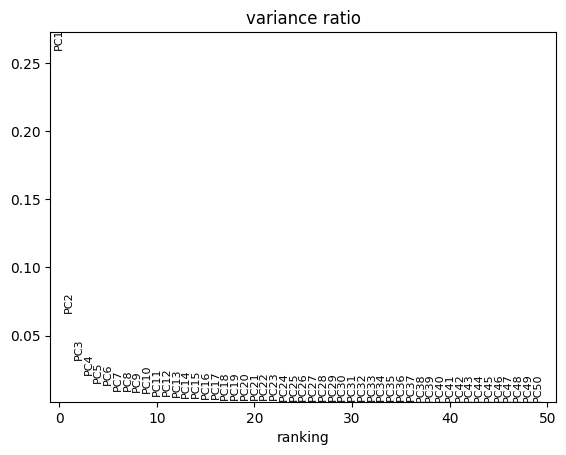

In [30]:
sc.pl.pca_variance_ratio(adata_pre, n_pcs=50)

In [31]:
sc.pp.neighbors(adata_pre, n_neighbors=10, n_pcs=10)

/home/sreeram/miniconda3/envs/scanpy_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [32]:
sc.tl.umap(adata_pre)

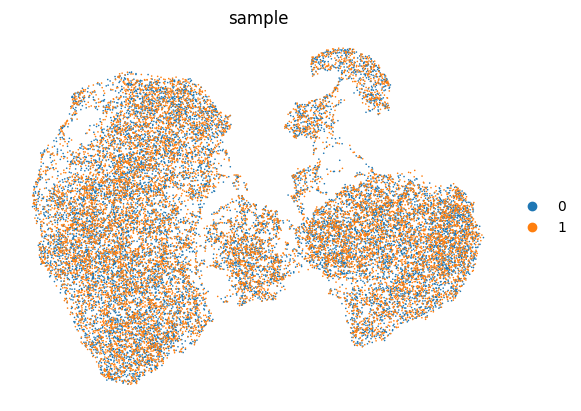

In [33]:
sc.pl.umap(adata_pre, 
           color=['sample'],
    ncols=3,
    frameon=False)

The cells are not grouped according to the samples, but this may not be the case always !!!

Demonstrating integration methods

##### Harmony integration

Harmony uses the PCs on the highly variable genes and generate adjusted PCs

In [34]:
adata_hvg

AnnData object with n_obs × n_vars = 22478 × 2000
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p'

In [35]:
sc.pp.pca(adata_hvg, n_comps=50)

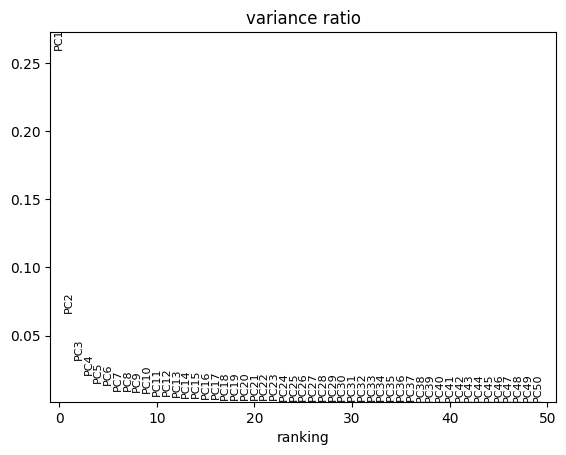

In [36]:
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=50)

In [37]:
adata_hvg

AnnData object with n_obs × n_vars = 22478 × 2000
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'

In [38]:
# %pip install harmonypy

In [39]:
adata_hvg.obsm['X_pca'].shape

(22478, 50)

In [40]:
print(adata_hvg.n_obs)

22478


In [41]:
print(adata_hvg.obs['sample'].isna().sum())

0


In [42]:
adata_hvg.obs['sample'] = adata_hvg.obs['sample'].astype('category')

In [43]:
adata_hvg

AnnData object with n_obs × n_vars = 22478 × 2000
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'

In [44]:
import harmonypy as hpy

In [45]:
pca_harmony = hpy.run_harmony(adata_hvg.obsm['X_pca'], meta_data = adata_hvg.obs,
                vars_use = 'sample', max_iter_harmony = 5, random_state = 198716)

/home/sreeram/miniconda3/envs/scanpy_env/lib/python3.10/site-packages/torch/cuda/__init__.py:180: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12090). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0
2026-04-20 17:25:05,996 - harmonypy - INFO - Running Harmony (PyTorch on cpu)
2026-04-20 17:25:05,997 - harmonypy - INFO -   Parameters:
2026-04-20 17:25:05,999 - harmonypy - INFO -     max_iter_harmony: 5
2026-04-20 17:25:06,001 - harmonypy - INFO -     max_iter_kmeans: 20
2026-04-20 17:25:06,002 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-04-20 17:25:06,003 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-04

In [46]:
adata_hvg.obsm['harmony'] = pca_harmony.Z_corr

In [47]:
sc.pp.neighbors(adata_hvg, n_neighbors=10, n_pcs=10, use_rep='harmony')
adata_hvg

AnnData object with n_obs × n_vars = 22478 × 2000
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p', 'pca', 'neighbors'
    obsm: 'X_pca', 'harmony'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [48]:
sc.tl.umap(adata_hvg)

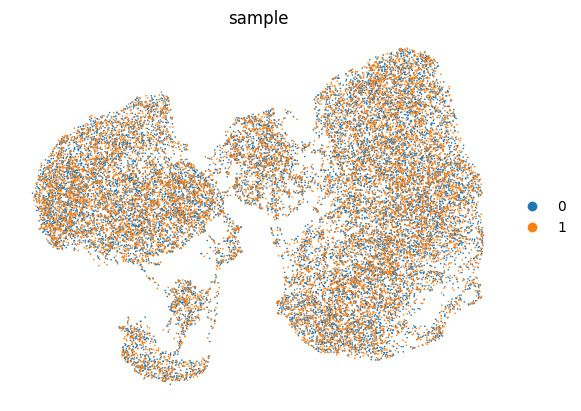

In [49]:
sc.pl.umap(adata_hvg, 
           color=['sample'],
       frameon=False)

In [50]:
# lets create groups based on QC violin plots and view them in UMAP
mt_cutoff = 5
ribo_cutoff = 25
n_genes_low = 2000

adata_hvg.obs['mt_group'] = np.where(adata_hvg.obs['pct_counts_mt'] < mt_cutoff, 'low_mt', 'high_mt')
adata_hvg.obs['ribo_group'] = np.where(adata_hvg.obs['pct_counts_ribo'] < ribo_cutoff, 'low_ribo', 'high_ribo')
adata_hvg.obs['n_genes_group'] = np.where(adata_hvg.obs['n_genes_by_counts'] < n_genes_low, 'low_n_genes', 'high_n_genes')
adata_hvg.obs.head()

,sample,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,mt_group,ribo_group,n_genes_group
AAACCCAAGTCAACAA-1,0,1323,4218.0,49.0,1.161688,1628.0,38.596489,low_mt,high_ribo,low_n_genes
AAACCCAAGTTAGAAC-1,0,2777,8030.0,207.0,2.577833,2175.0,27.085928,low_mt,high_ribo,high_n_genes
AAACCCAAGTTGAATG-1,0,2197,9067.0,171.0,1.885960,3682.0,40.608803,low_mt,high_ribo,high_n_genes
AAACCCAAGTTGGGAC-1,0,2289,6640.0,197.0,2.966867,2227.0,33.539158,low_mt,high_ribo,high_n_genes
AAACCCACAACCGGAA-1,0,1793,8478.0,93.0,1.096957,4205.0,49.598961,low_mt,high_ribo,low_n_genes


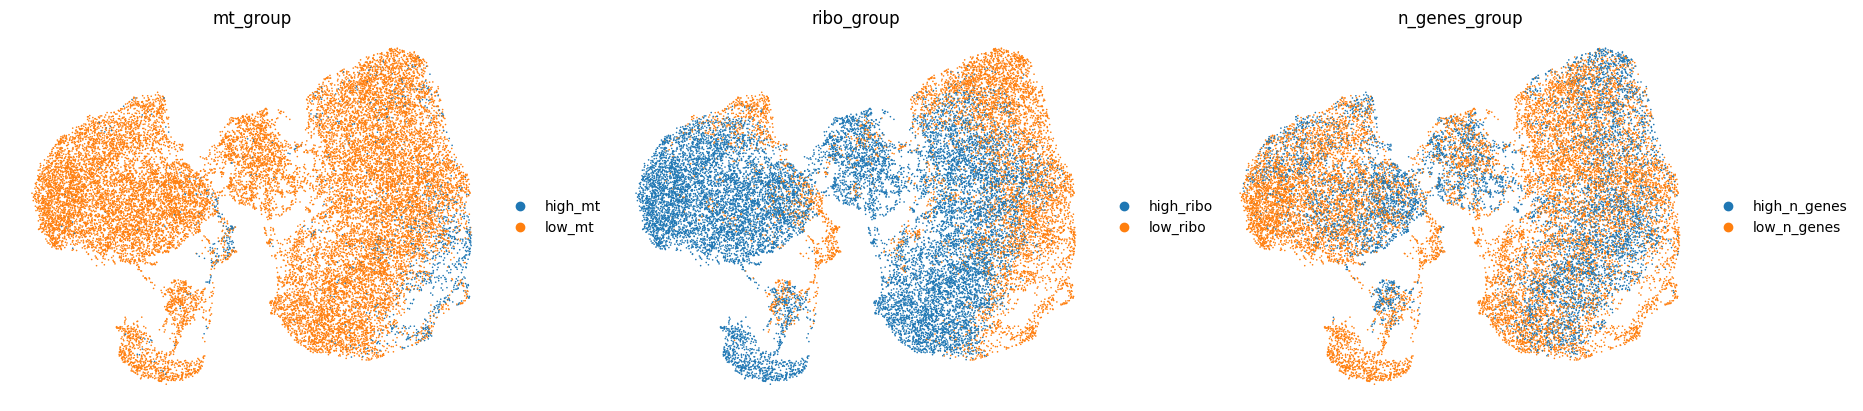

In [51]:
sc.pl.umap(
    adata_hvg,
    color=['mt_group', 'ribo_group', 'n_genes_group'],
    ncols=3,
    frameon=False
)


Distinct clusters (even before clustering) were found in ribosomal percent and highly expressing cells.

Low ribosomal expressing cells had more expressing genes

In [52]:
sc.write(adata=adata_hvg, filename='sam1_2_merged_harmony.h5ad')


#### Clustering

In [53]:
adata_hvg

AnnData object with n_obs × n_vars = 22478 × 2000
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'mt_group', 'ribo_group', 'n_genes_group'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'sample_colors', 'mt_group_colors', 'ribo_group_colors', 'n_genes_group_colors'
    obsm: 'X_pca', 'harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [54]:
sc.tl.leiden(adata=adata_hvg, resolution=0.5, random_state=198716, key_added='leiden_0.5', neighbors_key = 'neighbors',
             n_iterations = 10) # default runs until convergence

/tmp/ipykernel_4245/2134993917.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata=adata_hvg, resolution=0.5, random_state=198716, key_added='leiden_0.5', neighbors_key = 'neighbors',


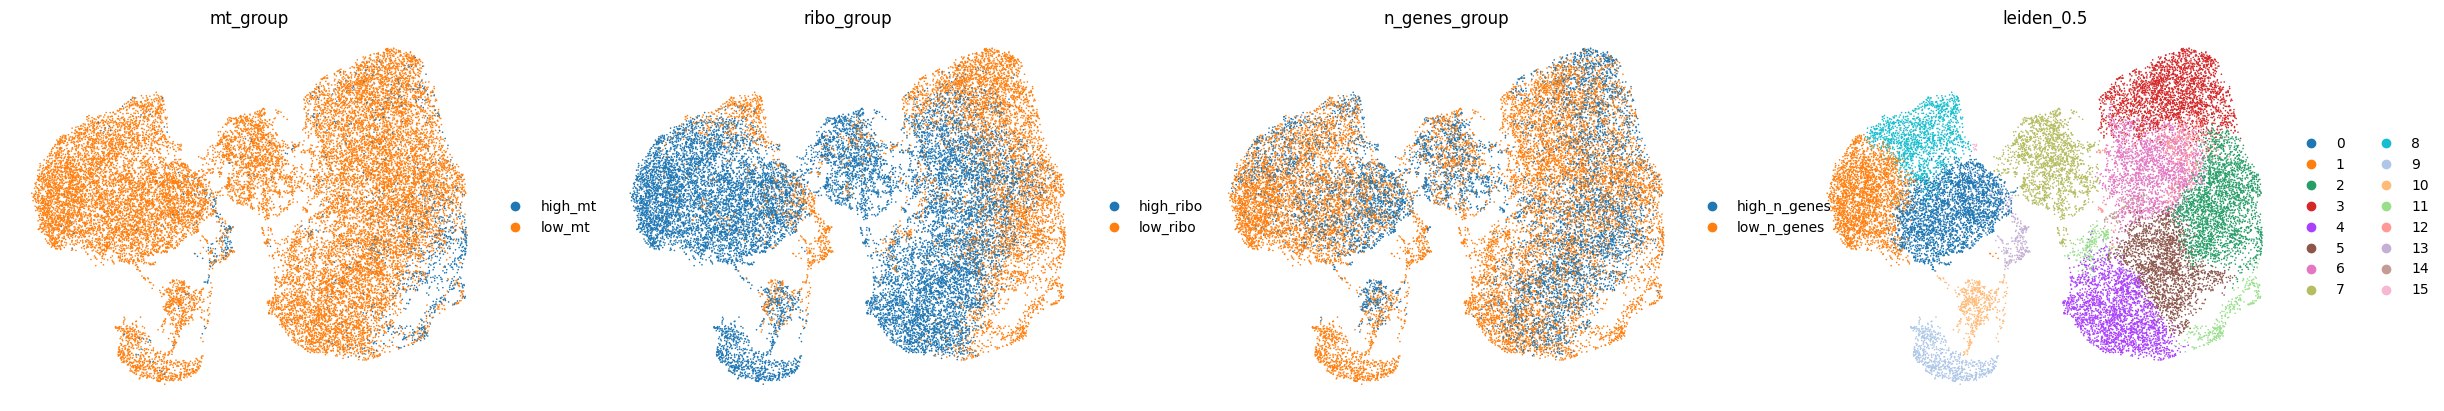

In [55]:
sc.pl.umap(
    adata_hvg,
    color=['mt_group', 'ribo_group', 'n_genes_group', 'leiden_0.5'],
    ncols=4,
    frameon=False
)


Cluster-specific DEGs

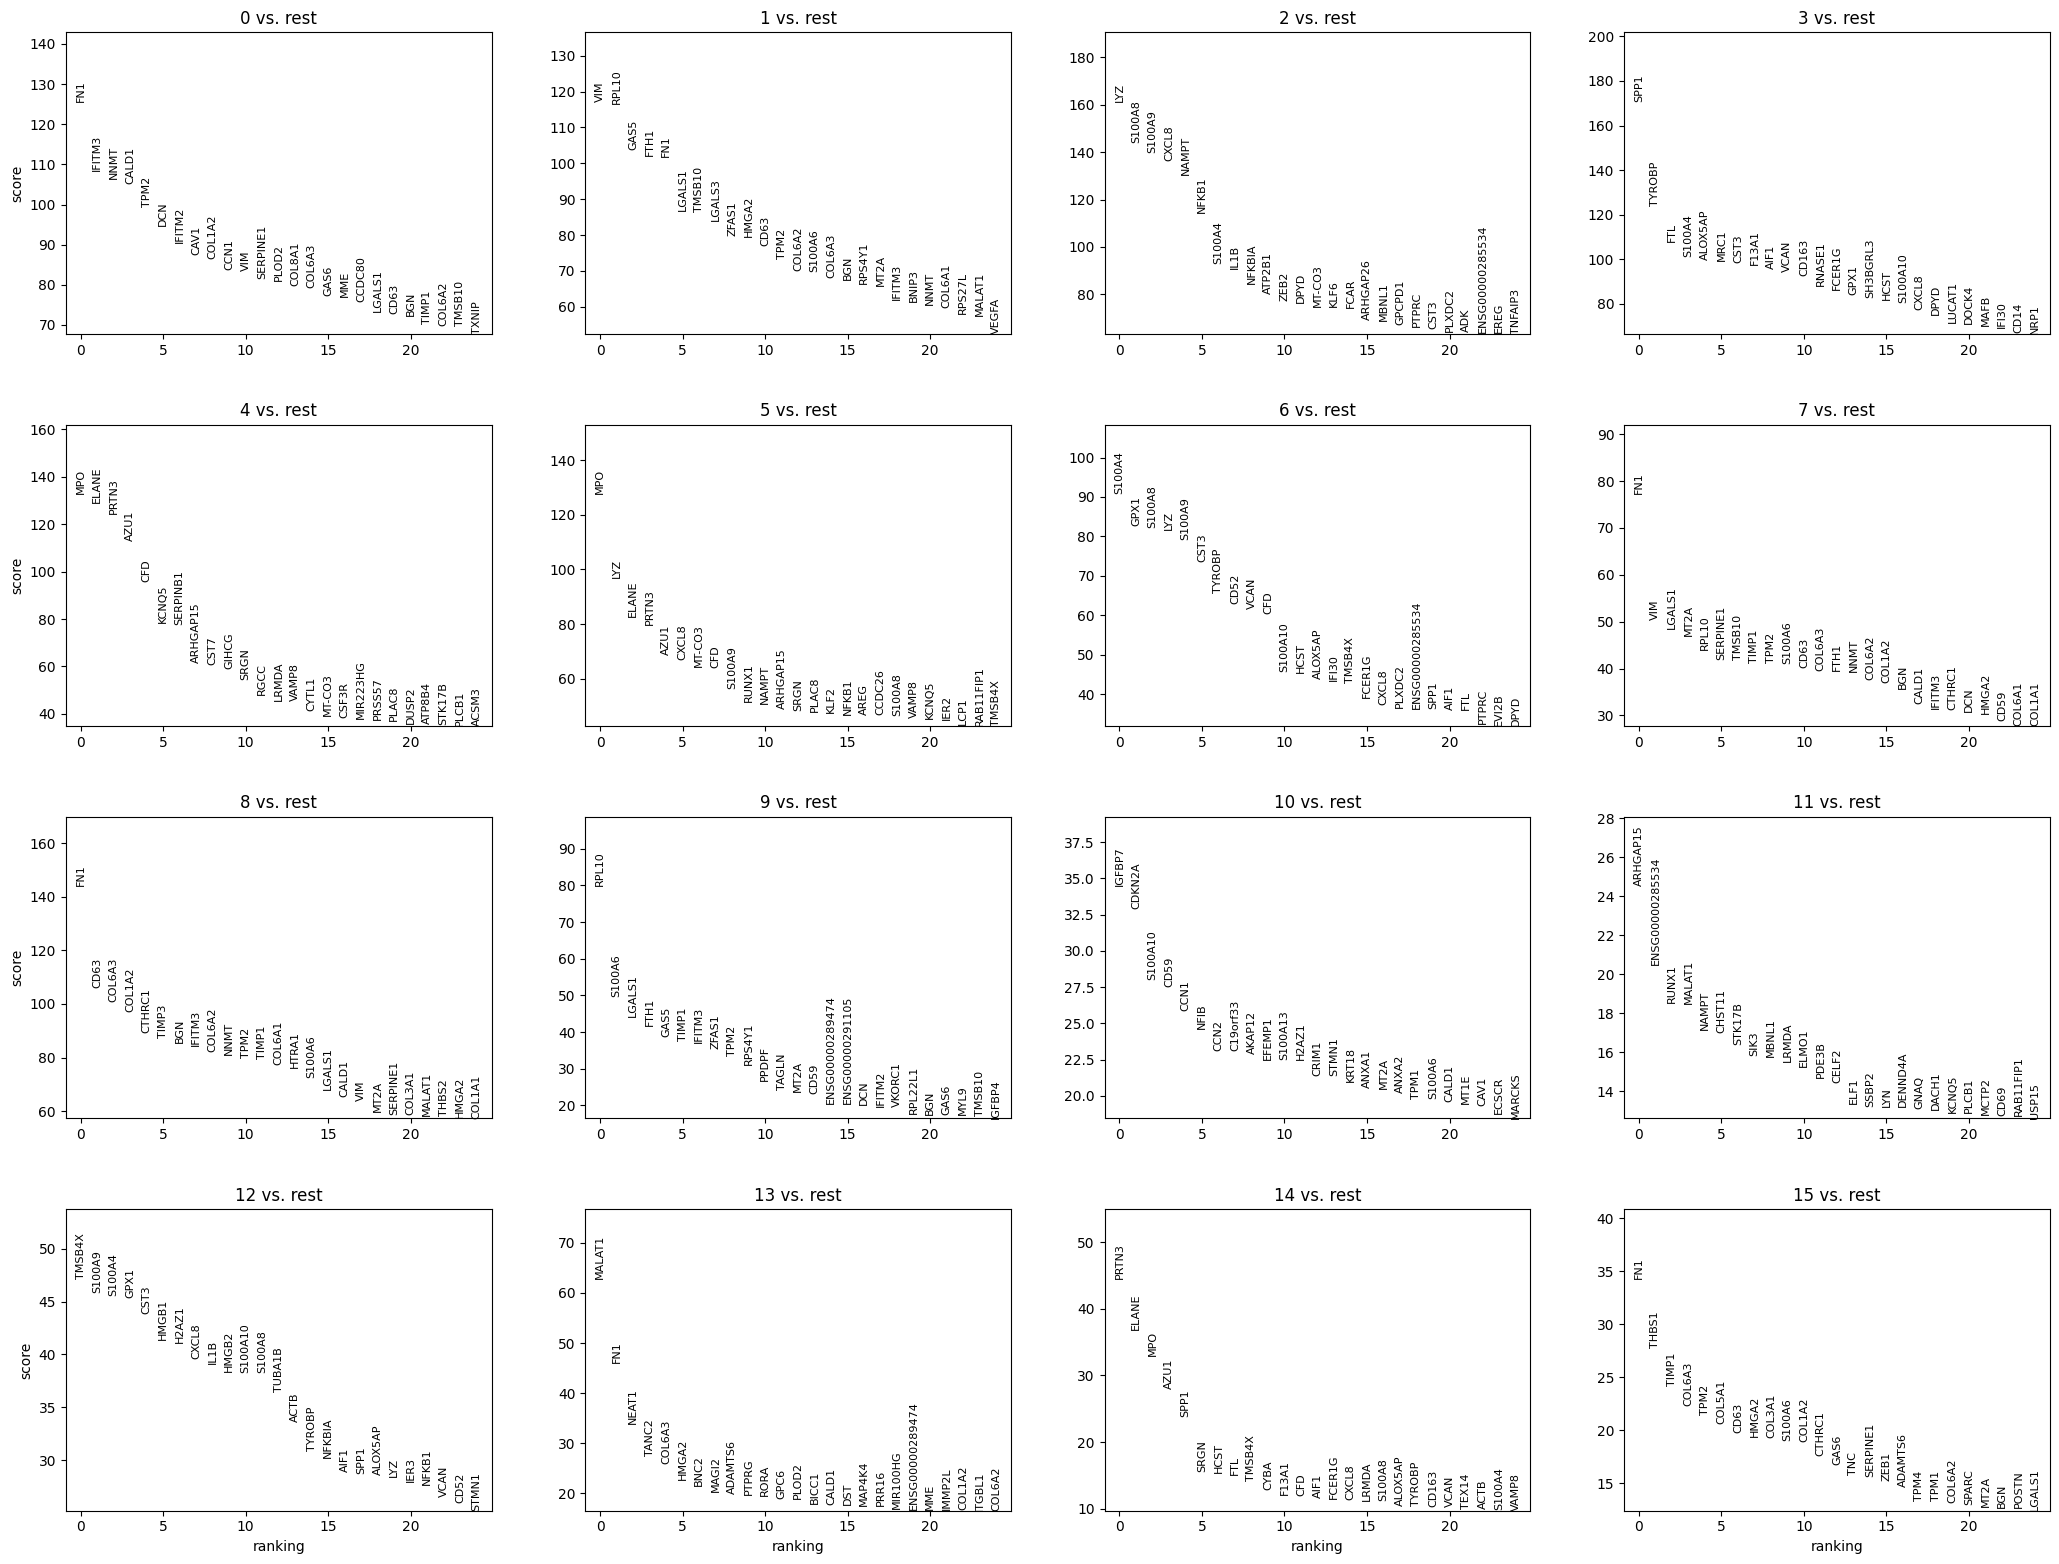

In [56]:
sc.tl.rank_genes_groups(adata_hvg, "leiden_0.5", method="t-test")
sc.pl.rank_genes_groups(adata_hvg, n_genes=25, sharey=False)

In [57]:
# Convert rank_genes_groups to a dataframe
rank_df = sc.get.rank_genes_groups_df(adata_hvg, None)

# Get top 5 genes per cluster
top5 = (
    rank_df.groupby("group")
           .head(5)
           .sort_values(["group", "logfoldchanges"], ascending=[True, False])
)

top5_genes = top5["names"].unique().tolist()
top5_genes

/tmp/ipykernel_4245/899141795.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rank_df.groupby("group")


['NNMT',
 'FN1',
 'CALD1',
 'TPM2',
 'IFITM3',
 'GAS5',
 'FTH1',
 'VIM',
 'RPL10',
 'S100A9',
 'S100A8',
 'LYZ',
 'CXCL8',
 'NAMPT',
 'SPP1',
 'ALOX5AP',
 'TYROBP',
 'S100A4',
 'FTL',
 'PRTN3',
 'ELANE',
 'AZU1',
 'MPO',
 'CFD',
 'GPX1',
 'MT2A',
 'LGALS1',
 'CTHRC1',
 'COL1A2',
 'COL6A3',
 'CD63',
 'S100A6',
 'CDKN2A',
 'IGFBP7',
 'CCN1',
 'CD59',
 'S100A10',
 'ARHGAP15',
 'ENSG00000285534',
 'RUNX1',
 'MALAT1',
 'CST3',
 'TMSB4X',
 'TANC2',
 'NEAT1',
 'THBS1',
 'TIMP1']

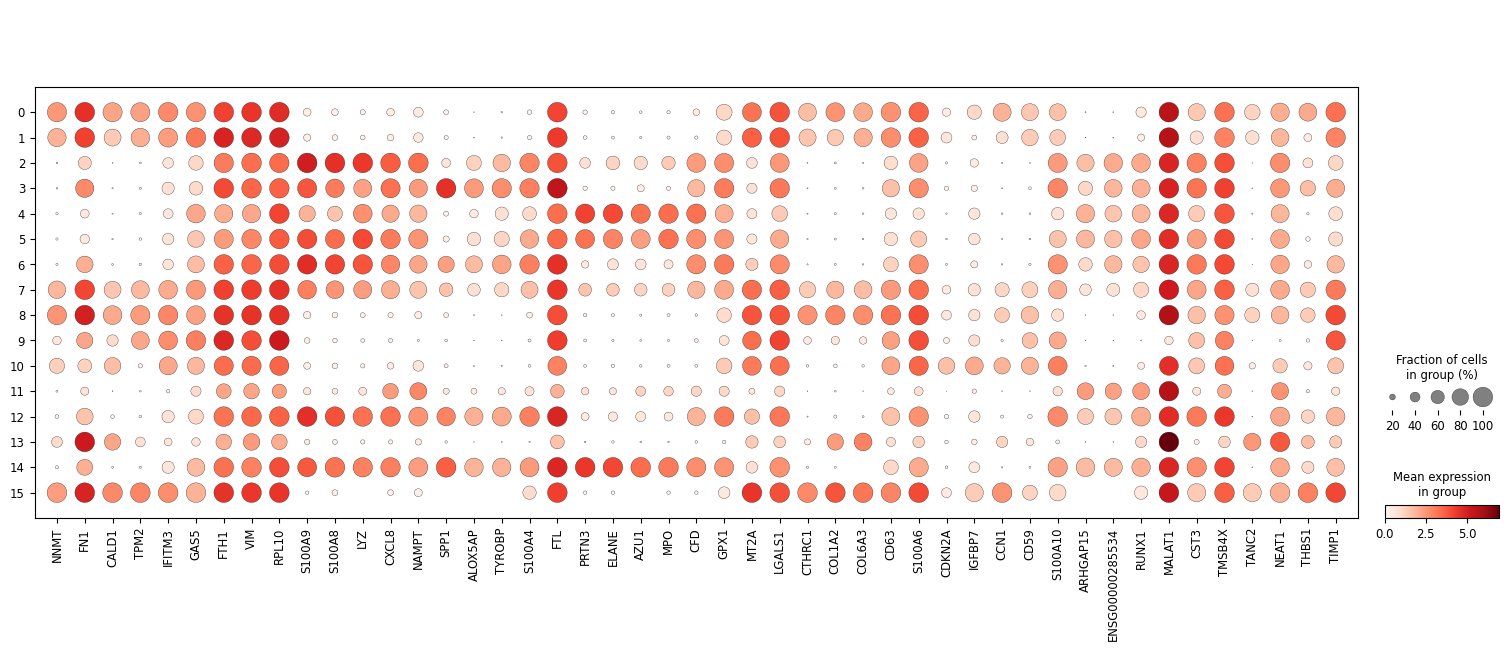

In [58]:
sc.pl.dotplot(adata_hvg, var_names=top5_genes, groupby="leiden_0.5")

In [59]:
sc.write(adata=adata_hvg, filename='sam1_2_clustered.h5ad')

#### Cell type annotation

Marker genes are from the single-cell best practices guide

In [60]:
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    "ID2-hi myeloid prog": [
        "CD14",
        "ID2",
        "VCAN",
        "S100A9",
        "CLEC12A",
        "KLF4",
        "PLAUR",
    ],
    "cDC1": ["CLEC9A", "CADM1"],
    "cDC2": [
        "CST3",
        "COTL1",
        "LYZ",
        "DMXL2",
        "CLEC10A",
        "FCER1A",
    ],  # Note: DMXL2 should be negative
    "Normoblast": ["SLC4A1", "SLC25A37", "HBB", "HBA2", "HBA1", "TFRC"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    "Proerythroblast": [
        "CDK6",
        "SYNGR1",
        "HBM",
        "GYPA",
    ],  # Note HBM and GYPA are negative markers
    "NK": ["GNLY", "NKG7", "CD247", "GRIK4", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Lymph prog": [
        "VPREB1",
        "MME",
        "EBF1",
        "SSBP2",
        "BACH2",
        "CD79B",
        "IGHM",
        "PAX5",
        "PRKCE",
        "DNTT",
        "IGLL1",
    ],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    "B1 B": [
        "MS4A1",
        "SSPN",
        "ITGB1",
        "EPHA4",
        "COL4A4",
        "PRDM1",
        "IRF4",
        "CD38",
        "XBP1",
        "PAX5",
        "BCL11A",
        "BLK",
        "IGHD",
        "IGHM",
        "ZNF215",
    ],  # Note IGHD and IGHM are negative markers
    "Transitional B": ["MME", "CD38", "CD24", "ACSM3", "MSI2"],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    "Plasmablast": ["XBP1", "RF4", "PRDM1", "PAX5"],  # Note PAX5 is a negative marker
    "CD4+ T activated": ["CD4", "IL7R", "TRBC2", "ITGB1"],
    "CD4+ T naive": ["CD4", "IL7R", "TRBC2", "CCR7"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T activation": ["CD69", "CD38"],  # CD69 much better marker!
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
    "G/M prog": ["MPO", "BCL2", "KCNQ5", "CSF3R"],
    "HSC": ["NRIP1", "MECOM", "PROM1", "NKAIN2", "CD34"],
    "MK/E prog": [
        "ZNF385D",
        "ITGA2B",
        "RYR3",
        "PLCB1",
    ],  # Note PLCB1 is a negative marker
}

In [61]:
marker_genes_in_data = {}
for ct, markers in marker_genes.items():
    markers_found = []
    for marker in markers:
        if marker in adata_hvg.var.index:
            markers_found.append(marker)
    marker_genes_in_data[ct] = markers_found

In [62]:
B_plasma_cts = [
    "Naive CD20+ B",
    "B1 B",
    "Transitional B",
    "Plasma cells",
    "Plasmablast",
]

In [63]:
marker_genes_filtered = {
    ct: [g for g in genes if g in adata_hvg.var_names]
    for ct, genes in marker_genes.items()
}

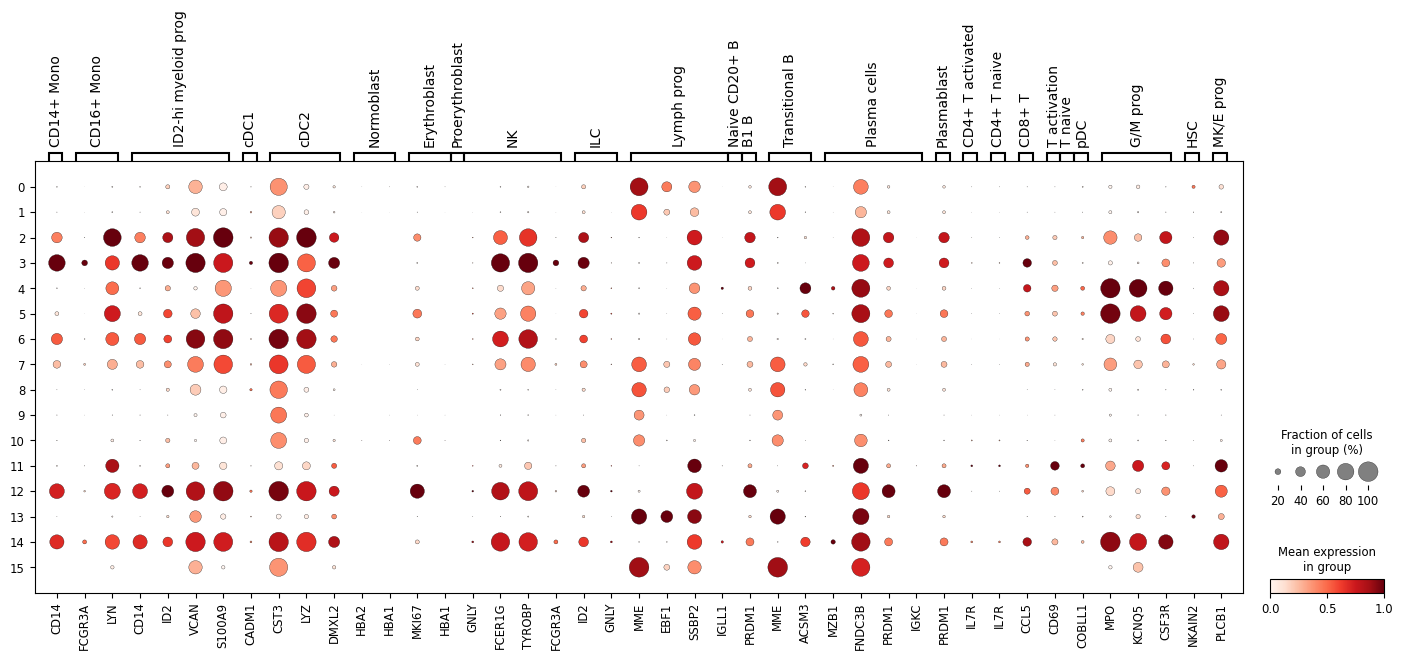

In [64]:
sc.pl.dotplot(
    adata_hvg,
    groupby="leiden_0.5",
    var_names=marker_genes_filtered,
    standard_scale="var",  # standard scale: normalize each gene to range from 0 to 1
)

score = average expression of the target gene set - average expression of a randomly sampled reference set of genes

In [65]:
# 2. Calculate a "score" for each cell for each marker group
for cell_type, genes in marker_genes.items():
    # Check if genes exist in dataset to avoid errors
    valid_genes = [g for g in genes if g in adata_hvg.var_names]
    if valid_genes:
        sc.tl.score_genes(adata_hvg, valid_genes, score_name=cell_type)

In [66]:
adata_hvg

AnnData object with n_obs × n_vars = 22478 × 2000
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'mt_group', 'ribo_group', 'n_genes_group', 'leiden_0.5', 'CD14+ Mono', 'CD16+ Mono', 'ID2-hi myeloid prog', 'cDC1', 'cDC2', 'Normoblast', 'Erythroblast', 'NK', 'ILC', 'Lymph prog', 'B1 B', 'Transitional B', 'Plasma cells', 'Plasmablast', 'CD4+ T activated', 'CD4+ T naive', 'CD8+ T', 'T activation', 'pDC', 'G/M prog', 'HSC', 'MK/E prog'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'sample_colors', 'mt_group_colors', 'ribo_group_colors', 'n_genes_group_colors', 'leiden_0.5', 'leiden_0.5_colors', 'rank_genes_groups'
    obsm: 'X_pca', 'harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [67]:
score_columns = list(marker_genes.keys())
score_columns = [i for i in score_columns if i in adata_hvg.obs.columns]
# Create a dataframe of scores indexed by cluster
cluster_scores = adata_hvg.obs.groupby('leiden_0.5')[score_columns].mean()

# Assign the label with the highest score to each cluster
# idxmax returns the column name (Cell Type) with the highest value for each row (Cluster)
predicted_labels = cluster_scores.idxmax(axis=1)

# Map these predictions back to the adata object
adata_hvg.obs['predicted_cell_type'] = adata_hvg.obs['leiden_0.5'].map(predicted_labels)

/tmp/ipykernel_4245/1124310314.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_scores = adata_hvg.obs.groupby('leiden_0.5')[score_columns].mean()


In [68]:
adata_hvg.obs['predicted_cell_type'].value_counts()

predicted_cell_type
cDC2                   8275
Transitional B         8205
ID2-hi myeloid prog    2912
G/M prog               2328
T activation            489
Lymph prog              269
Name: count, dtype: int64

In [69]:
adata_hvg

AnnData object with n_obs × n_vars = 22478 × 2000
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'mt_group', 'ribo_group', 'n_genes_group', 'leiden_0.5', 'CD14+ Mono', 'CD16+ Mono', 'ID2-hi myeloid prog', 'cDC1', 'cDC2', 'Normoblast', 'Erythroblast', 'NK', 'ILC', 'Lymph prog', 'B1 B', 'Transitional B', 'Plasma cells', 'Plasmablast', 'CD4+ T activated', 'CD4+ T naive', 'CD8+ T', 'T activation', 'pDC', 'G/M prog', 'HSC', 'MK/E prog', 'predicted_cell_type'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'sample_colors', 'mt_group_colors', 'ribo_group_colors', 'n_genes_group_colors', 'leiden_0.5', 'leiden_0.5_colors', 'rank_genes_groups'
    obsm: 'X_pca', 'harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

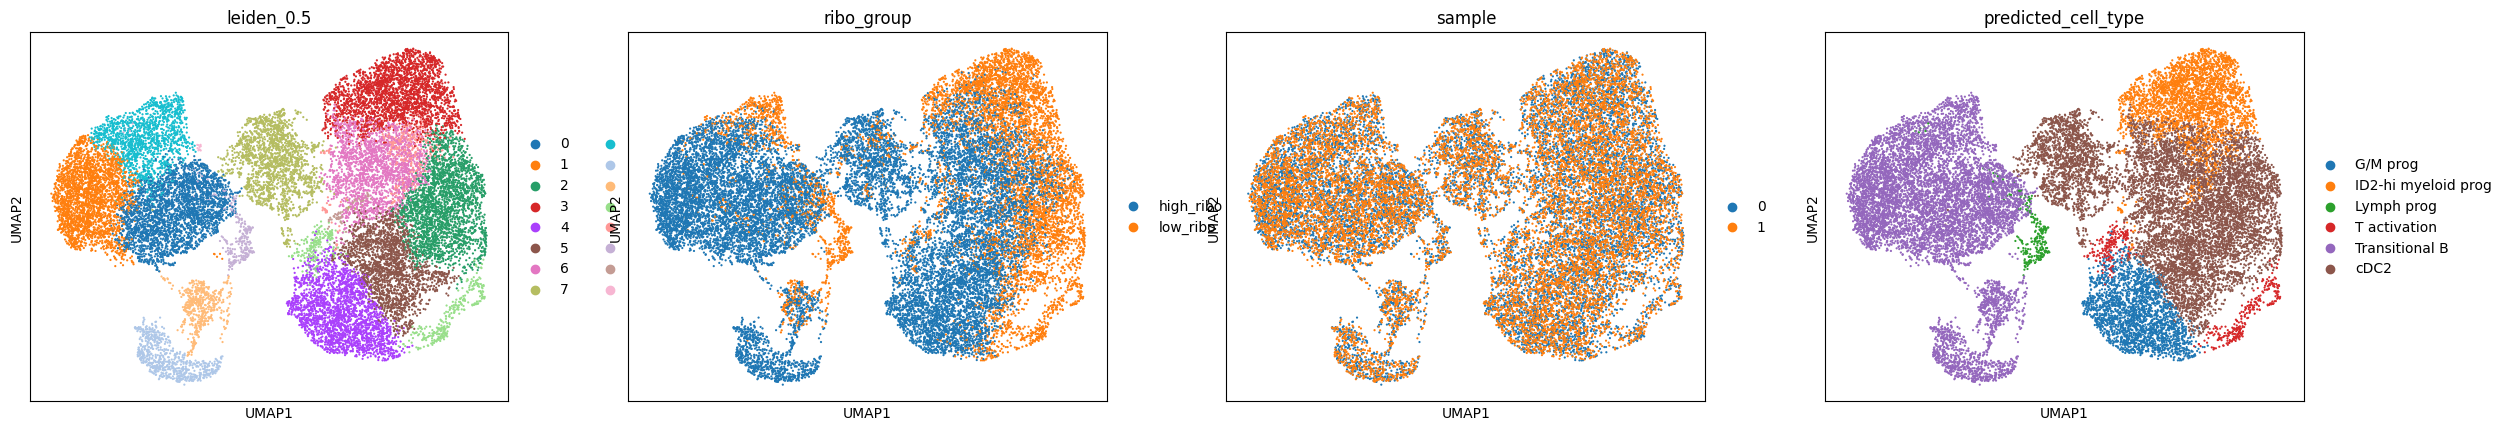

In [70]:
sc.pl.umap(adata=adata_hvg, color=['leiden_0.5', 'ribo_group', 'sample', 'predicted_cell_type'], size=10, ncols=4)

In [71]:
pd.crosstab(adata_hvg.obs['predicted_cell_type'], adata_hvg.obs['sample'])

sample,0,1
predicted_cell_type,,
G/M prog,1171,1157
ID2-hi myeloid prog,1448,1464
Lymph prog,135,134
T activation,244,245
Transitional B,4097,4108
cDC2,4124,4151


In [72]:
sc.write(adata=adata_hvg, filename='sam1_2_clustered_annotated.h5ad')

#### Trajectory inference

In [73]:
import os
import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [74]:
adata_hvg = sc.read_h5ad('sam1_2_clustered_annotated.h5ad')

/home/sreeram/miniconda3/envs/scanpy_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [75]:
# %pip install fa2-modified

In [76]:
sc.tl.diffmap(adata_hvg)

In [77]:
root_ixs = adata_hvg.obsm["X_diffmap"][:, 3].argmin()

In [78]:
adata_hvg

AnnData object with n_obs × n_vars = 22478 × 2000
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'mt_group', 'ribo_group', 'n_genes_group', 'leiden_0.5', 'CD14+ Mono', 'CD16+ Mono', 'ID2-hi myeloid prog', 'cDC1', 'cDC2', 'Normoblast', 'Erythroblast', 'NK', 'ILC', 'Lymph prog', 'B1 B', 'Transitional B', 'Plasma cells', 'Plasmablast', 'CD4+ T activated', 'CD4+ T naive', 'CD8+ T', 'T activation', 'pDC', 'G/M prog', 'HSC', 'MK/E prog', 'predicted_cell_type'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'leiden_0.5', 'leiden_0.5_colors', 'log1p', 'mt_group_colors', 'n_genes_group_colors', 'neighbors', 'pca', 'predicted_cell_type_colors', 'rank_genes_groups', 'ribo_group_colors', 'sample_colors', 'umap', 'diffmap_evals'
    obsm: 'X_pca', 'X_umap', 'harmony', 'X_diffmap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

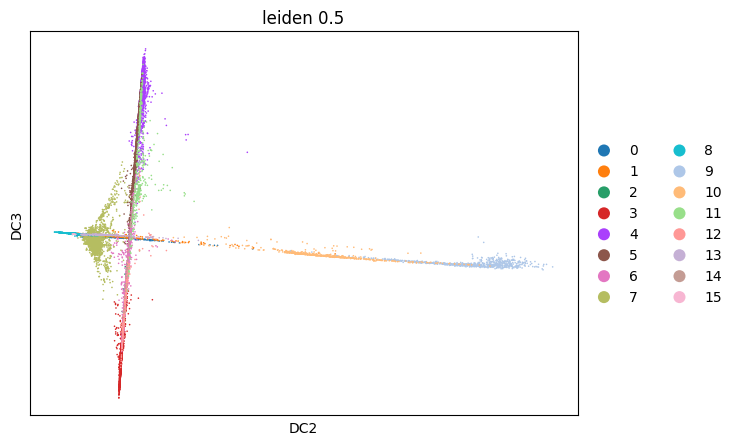

In [79]:
sc.pl.scatter(
    adata_hvg,
    basis="diffmap",
    color=["leiden_0.5"],
    components=[2,3],
)

In [80]:
adata_hvg.uns["iroot"] = root_ixs

In [81]:
sc.tl.dpt(adata_hvg)

In [82]:
adata_hvg

AnnData object with n_obs × n_vars = 22478 × 2000
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'mt_group', 'ribo_group', 'n_genes_group', 'leiden_0.5', 'CD14+ Mono', 'CD16+ Mono', 'ID2-hi myeloid prog', 'cDC1', 'cDC2', 'Normoblast', 'Erythroblast', 'NK', 'ILC', 'Lymph prog', 'B1 B', 'Transitional B', 'Plasma cells', 'Plasmablast', 'CD4+ T activated', 'CD4+ T naive', 'CD8+ T', 'T activation', 'pDC', 'G/M prog', 'HSC', 'MK/E prog', 'predicted_cell_type', 'dpt_pseudotime'
    var: 'gene', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'leiden_0.5', 'leiden_0.5_colors', 'log1p', 'mt_group_colors', 'n_genes_group_colors', 'neighbors', 'pca', 'predicted_cell_type_colors', 'rank_genes_groups', 'ribo_group_colors', 'sample_colors', 'umap', 'diffmap_evals', 'iroot'
    obsm: 'X_pca', 'X_umap', 'harmony', 'X_diffmap'
    varm: 'PCs'
    obsp: 'conn

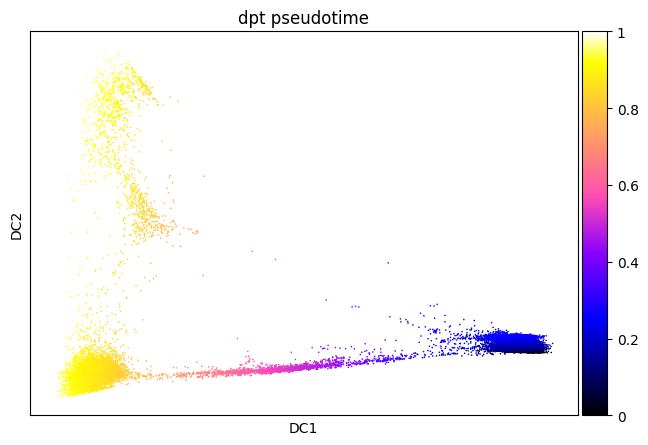

In [83]:
sc.pl.scatter(
    adata_hvg,
    basis="diffmap",
    color=["dpt_pseudotime"],
    color_map="gnuplot2",
)

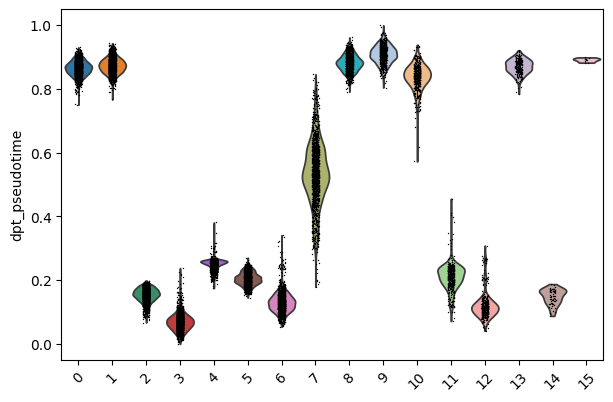

In [84]:
sc.pl.violin(
    adata_hvg,
    keys=["dpt_pseudotime"],
    groupby="leiden_0.5",
    rotation=45)

In [85]:
pd.crosstab(adata_hvg.obs['predicted_cell_type'], adata_hvg.obs['leiden_0.5'])

leiden_0.5,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
predicted_cell_type,,,,,,,,,,,,,,,,
G/M prog,0,0,0,0,2328,0,0,0,0,0,0,0,0,0,0,0
ID2-hi myeloid prog,0,0,0,2483,0,0,0,0,0,0,0,0,429,0,0,0
Lymph prog,0,0,0,0,0,0,0,0,0,0,0,0,0,269,0,0
T activation,0,0,0,0,0,0,0,0,0,0,0,489,0,0,0,0
Transitional B,2868,2616,0,0,0,0,0,0,1477,722,512,0,0,0,0,10
cDC2,0,0,2505,0,0,1985,1967,1752,0,0,0,0,0,0,66,0


In [86]:
sc.write(adata = adata_hvg, filename='sam1_2_dpt_based.h5ad')

Lineages are mixed, lineage specific subsets can be used to infer pseudotime and trajectories